# Supplier Lead Time Analysis

Which suppliers deliver late, which are unpredictable, and does lateness go together with poor quality?

> **Note:** all data in this project is synthetic. It was generated with `generate_data.py` and does not come from any real company.

**Contents**
1. Load and check the data
2. Supplier delivery performance
3. Is delay related to defects and waste?
4. Country comparison
5. Supplier risk ranking
6. Conclusions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
BLUE, RED, GREY = "#2b6cb0", "#c53030", "#a0aec0"

## 1. Load and check the data

In [2]:
df = pd.read_csv("data/orders.csv", parse_dates=["order_date"])

# delay = actual - promised lead time (positive = late, negative = early)
df["delay_days"] = df["actual_days"] - df["promised_days"]
df["is_late"] = df["delay_days"] > 0

print(f"{len(df)} orders, {df['supplier_id'].nunique()} suppliers, "
      f"{df['order_date'].min().date()} to {df['order_date'].max().date()}")
df.head()

600 orders, 20 suppliers, 2024-01-03 to 2025-12-30


,order_id,supplier_id,supplier_name,country,material,order_date,quantity,promised_days,actual_days,defect_rate_pct,waste_pct,delay_days,is_late
0,PO0160,S20,Supplier 20,Italy,Aluminium alloy,2024-01-03,1808,42,41,3.05,5.02,-1,False
1,PO0179,S12,Supplier 12,Germany,Machined parts,2024-01-07,870,28,31,4.08,6.76,3,True
2,PO0309,S08,Supplier 08,India,Aluminium alloy,2024-01-07,725,28,37,4.09,3.04,9,True
3,PO0008,S08,Supplier 08,India,Cast steel,2024-01-08,1499,28,35,3.11,3.03,7,True
4,PO0027,S17,Supplier 17,Finland,Machined parts,2024-01-09,262,35,37,0.35,5.47,2,True


In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate orders:", int(df["order_id"].duplicated().sum()))
df[["promised_days", "actual_days", "delay_days", "defect_rate_pct", "waste_pct"]].describe().round(2)

Missing values: 0
Duplicate orders: 0


,promised_days,actual_days,delay_days,defect_rate_pct,waste_pct
count,600.00,600.00,600.00,600.00,600.00
mean,27.50,30.75,3.25,2.29,4.01
std,10.69,11.40,4.74,1.30,1.99
min,14.00,10.00,-15.00,0.00,0.00
25%,14.00,21.00,0.00,1.22,2.56
50%,28.00,29.00,3.00,2.23,4.09
75%,42.00,41.00,6.00,3.31,5.41
max,42.00,58.00,21.00,5.80,11.26


Overall, the average order arrives a few days late. The next step is to see how this varies by supplier.

In [4]:
print(f"Average delay:       {df['delay_days'].mean():.1f} days")
print(f"Median delay:        {df['delay_days'].median():.0f} days")
print(f"Orders delivered late: {df['is_late'].mean():.0%}")

Average delay:       3.3 days
Median delay:        3 days
Orders delivered late: 73%


## 2. Supplier delivery performance

For each supplier we look at the **average delay** (how late), the **share of late orders**, and the **standard deviation of delay** (how unpredictable).

In [5]:
suppliers = (
    df.groupby("supplier_name")
      .agg(orders=("order_id", "count"),
           country=("country", "first"),
           avg_delay=("delay_days", "mean"),
           delay_std=("delay_days", "std"),
           late_share=("is_late", "mean"),
           avg_defect_pct=("defect_rate_pct", "mean"),
           avg_waste_pct=("waste_pct", "mean"))
      .round(2)
      .sort_values("avg_delay", ascending=False)
)
suppliers

,orders,country,avg_delay,delay_std,late_share,avg_defect_pct,avg_waste_pct
supplier_name,,,,,,,
Supplier 08,23,India,8.78,4.76,1.00,3.62,3.46
Supplier 07,19,Italy,7.26,3.28,1.00,1.08,1.21
Supplier 01,26,Turkey,6.58,2.37,1.00,0.89,1.49
Supplier 04,31,Italy,6.26,1.50,1.00,1.88,3.40
Supplier 06,34,Italy,5.91,3.65,0.97,3.78,3.37
Supplier 10,27,Turkey,5.89,4.57,0.89,1.44,4.14
Supplier 20,25,Italy,5.60,5.00,0.84,0.93,5.13
Supplier 18,33,Germany,5.27,4.78,0.82,1.35,5.83
Supplier 13,37,Poland,5.16,3.93,0.86,3.64,4.05


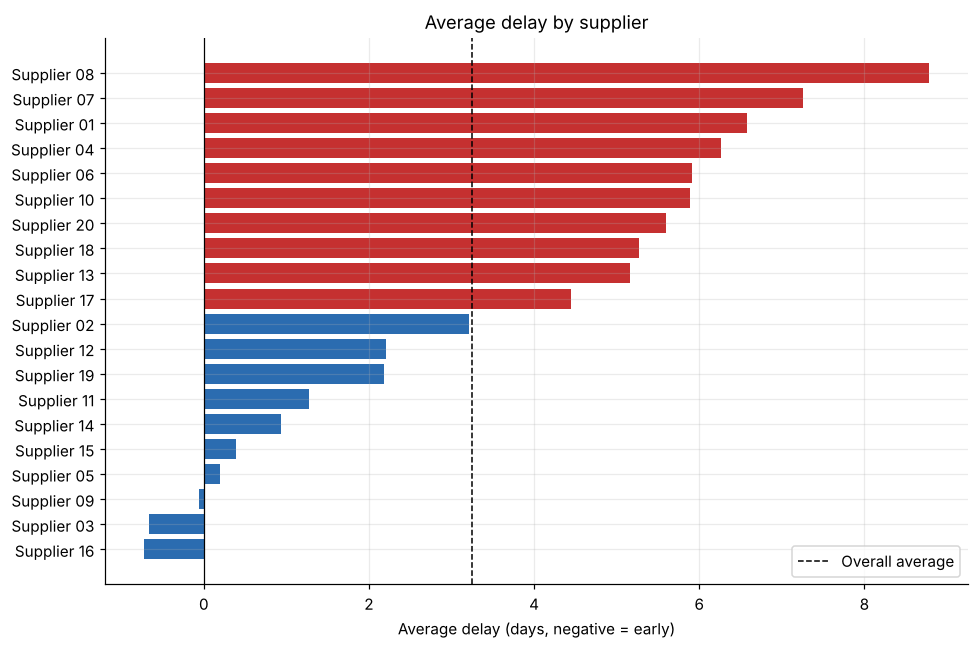

In [6]:
s = suppliers.sort_values("avg_delay")
colors = [RED if v > df["delay_days"].mean() else BLUE for v in s["avg_delay"]]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(s.index, s["avg_delay"], color=colors)
ax.axvline(df["delay_days"].mean(), color="black", ls="--", lw=1, label="Overall average")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Average delay (days, negative = early)")
ax.set_title("Average delay by supplier")
ax.legend()
plt.tight_layout()
plt.show()

Red bars are suppliers that are later than the overall average. A supplier can also be dangerous for planning even when its *average* is fine, if its deliveries are unpredictable. The chart below combines both views.

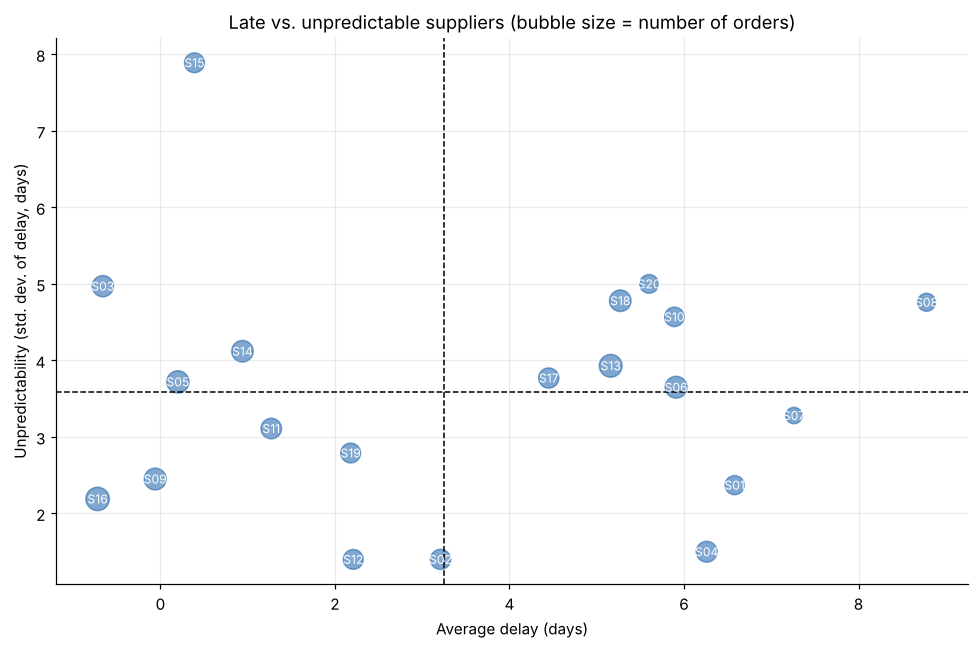

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(suppliers["avg_delay"], suppliers["delay_std"], s=suppliers["orders"] * 6, color=BLUE, alpha=0.6)
for name, r in suppliers.iterrows():
    ax.annotate(name.replace("Supplier ", "S"), (r["avg_delay"], r["delay_std"]),
                ha="center", va="center", fontsize=8, color="white")
ax.axvline(df["delay_days"].mean(), color="black", ls="--", lw=1)
ax.axhline(suppliers["delay_std"].mean(), color="black", ls="--", lw=1)
ax.set_xlabel("Average delay (days)")
ax.set_ylabel("Unpredictability (std. dev. of delay, days)")
ax.set_title("Late vs. unpredictable suppliers (bubble size = number of orders)")
plt.tight_layout()
plt.show()

- **Right side** of the chart: consistently late suppliers.
- **Top**: unpredictable suppliers, where delivery dates are hard to plan.
- **Top right**: late *and* unpredictable. These are the biggest planning risk.

## 3. Is delay related to defects and waste?

A common assumption is that a supplier that rushes or struggles with deadlines also delivers worse quality. Let's test it.

In [8]:
corr = df[["delay_days", "defect_rate_pct", "waste_pct"]].corr().round(2)
corr

,delay_days,defect_rate_pct,waste_pct
delay_days,1.00,-0.07,-0.04
defect_rate_pct,-0.07,1.00,0.10
waste_pct,-0.04,0.10,1.00


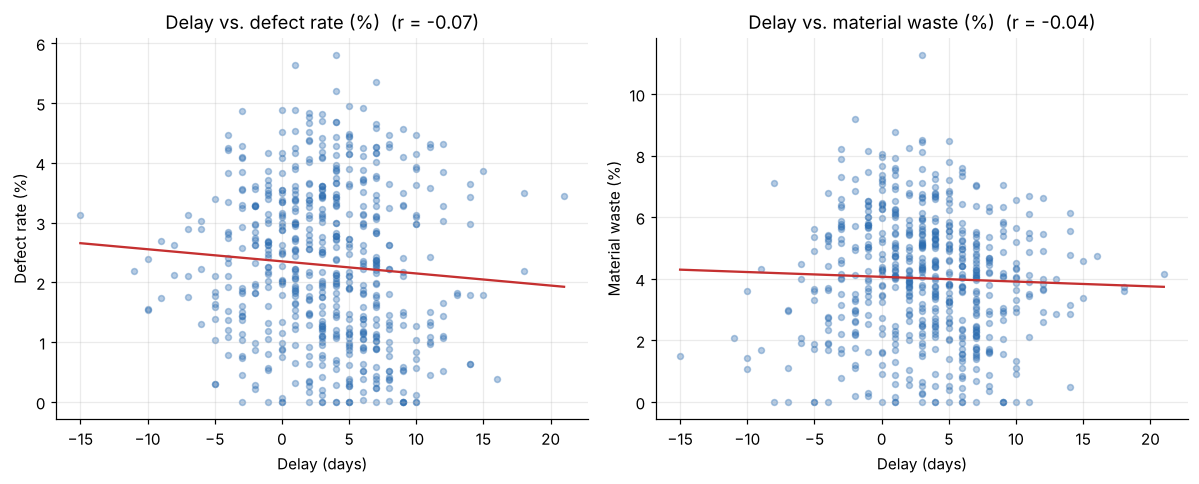

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, label in zip(axes, ["defect_rate_pct", "waste_pct"], ["Defect rate (%)", "Material waste (%)"]):
    ax.scatter(df["delay_days"], df[col], alpha=0.35, color=BLUE, s=15)
    m, b = np.polyfit(df["delay_days"], df[col], 1)
    xs = np.linspace(df["delay_days"].min(), df["delay_days"].max(), 50)
    ax.plot(xs, m * xs + b, color=RED)
    ax.set_xlabel("Delay (days)")
    ax.set_ylabel(label)
    ax.set_title(f"Delay vs. {label.lower()}  (r = {df['delay_days'].corr(df[col]):.2f})")
plt.tight_layout()
plt.show()

The correlations are close to zero and the trend lines are almost flat. **In this dataset, delay tells us essentially nothing about defect rate or waste.** Delivery performance and quality have to be judged separately.

## 4. Country comparison

In [10]:
countries = (
    df.groupby("country")
      .agg(orders=("order_id", "count"),
           avg_delay=("delay_days", "mean"),
           late_share=("is_late", "mean"),
           avg_defect_pct=("defect_rate_pct", "mean"),
           avg_waste_pct=("waste_pct", "mean"))
      .round(2)
      .sort_values("avg_delay", ascending=False)
)
countries

,orders,avg_delay,late_share,avg_defect_pct,avg_waste_pct
country,,,,,
Poland,37,5.16,0.86,3.64,4.05
Turkey,110,4.40,0.87,1.87,4.31
Italy,172,4.31,0.81,2.09,3.42
India,58,3.60,0.64,2.56,3.24
Finland,57,2.46,0.67,1.58,3.07
Germany,132,1.42,0.61,2.57,4.69
Spain,34,-0.06,0.44,2.72,6.28


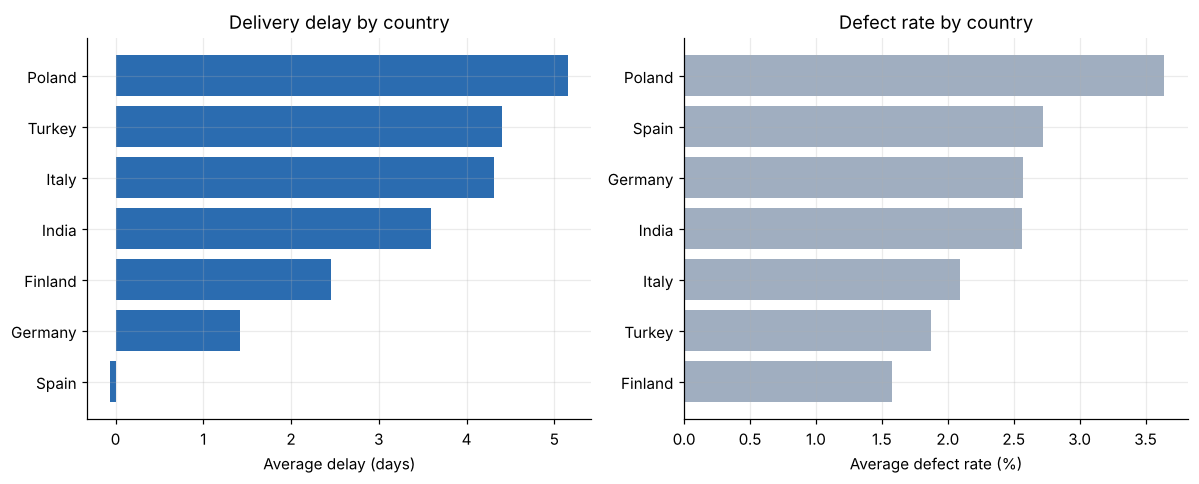

In [11]:
c = countries.sort_values("avg_delay")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(c.index, c["avg_delay"], color=BLUE)
axes[0].set_xlabel("Average delay (days)")
axes[0].set_title("Delivery delay by country")
c2 = countries.sort_values("avg_defect_pct")
axes[1].barh(c2.index, c2["avg_defect_pct"], color=GREY)
axes[1].set_xlabel("Average defect rate (%)")
axes[1].set_title("Defect rate by country")
plt.tight_layout()
plt.show()

Country is a rough guide only: each country has only 1 to 6 suppliers (Poland and Spain have just one) in this dataset, and the differences between suppliers inside one country are large. Treat this as context, not as a rule.

## 5. Supplier risk ranking

To rank suppliers, we combine five measures into one **risk score** (0 = best, 100 = worst). Each measure is scaled to 0-1 across suppliers and the scaled values are averaged with weights.

| Measure | Weight |
|---|---|
| Average delay | 30% |
| Unpredictability (std. dev. of delay) | 20% |
| Share of late orders | 20% |
| Defect rate | 20% |
| Material waste | 10% |

The weights are an assumption and can be changed to match business priorities.

In [12]:
weights = {"avg_delay": 0.30, "delay_std": 0.20, "late_share": 0.20,
           "avg_defect_pct": 0.20, "avg_waste_pct": 0.10}

scaled = (suppliers[list(weights)] - suppliers[list(weights)].min()) / \
         (suppliers[list(weights)].max() - suppliers[list(weights)].min())
suppliers["risk_score"] = (scaled * pd.Series(weights)).sum(axis=1).mul(100).round(1)

ranking = suppliers.sort_values("risk_score", ascending=False)
ranking[["country", "orders", "avg_delay", "delay_std", "late_share",
         "avg_defect_pct", "avg_waste_pct", "risk_score"]]

,country,orders,avg_delay,delay_std,late_share,avg_defect_pct,avg_waste_pct,risk_score
supplier_name,,,,,,,,
Supplier 08,India,23,8.78,4.76,1.00,3.62,3.46,82.3
Supplier 06,Italy,34,5.91,3.65,0.97,3.78,3.37,69.8
Supplier 13,Poland,37,5.16,3.93,0.86,3.64,4.05,65.3
Supplier 10,Turkey,27,5.89,4.57,0.89,1.44,4.14,56.1
Supplier 18,Germany,33,5.27,4.78,0.82,1.35,5.83,55.0
Supplier 20,Italy,25,5.60,5.00,0.84,0.93,5.13,53.3
Supplier 04,Italy,31,6.26,1.50,1.00,1.88,3.40,52.7
Supplier 19,Turkey,28,2.18,2.79,0.64,3.92,7.00,52.7
Supplier 07,Italy,19,7.26,3.28,1.00,1.08,1.21,52.3


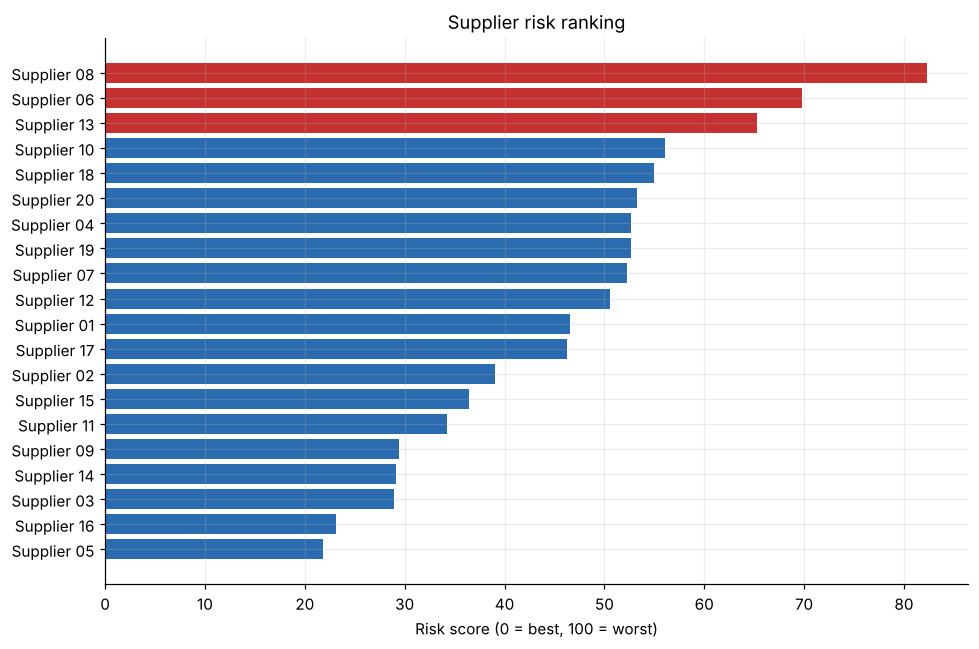

In [13]:
r = ranking.sort_values("risk_score")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(r.index, r["risk_score"], color=[RED if v >= 60 else BLUE for v in r["risk_score"]])
ax.set_xlabel("Risk score (0 = best, 100 = worst)")
ax.set_title("Supplier risk ranking")
plt.tight_layout()
plt.show()

In [14]:
suppliers.to_csv("data/supplier_summary.csv")
print("Saved data/supplier_summary.csv")

Saved data/supplier_summary.csv


## 6. Conclusions

**Delivery performance**
- On average, orders arrive **3.3 days late**, and 73% of orders are late.
- **Supplier 08** is the worst on delay (+8.8 days on average, late on every order). Suppliers 07, 01 and 04 are also late on every single order.
- **Supplier 15** is the least predictable (delay std. dev. of about 7.9 days) even though its average delay is small. Its average hides large swings in both directions.
- **Suppliers 16 and 03** deliver slightly *early* on average.

**Delay vs. quality**
- Delay has almost no correlation with defect rate (r = -0.07) or waste (r = -0.04). Late suppliers are not systematically worse on quality, so the two must be monitored separately.

**Countries**
- Poland (+5.2 days), Turkey (+4.4) and Italy (+4.3) have the largest average delays. Spain is the only country that is on time on average.
- Poland also has the highest defect rate (3.6%), but Poland is represented by a single supplier (Supplier 13).

**Risk ranking**
- The highest combined risk scores belong to **Supplier 08, Supplier 06 and Supplier 13**. Supplier 06 and 13 are late *and* have high defect rates, while Supplier 08 is the worst on delay and also has a high defect rate.
- Recommended focus: renegotiate lead times with Supplier 08, and start quality reviews with Suppliers 06 and 13.

**Limitations**
- The data is synthetic, so these numbers describe the simulated suppliers, not real ones.
- Each supplier has only 19 to 39 orders, so averages for individual suppliers are approximate.
- The risk score depends on the chosen weights.